# Email Spam Detection

## Project Overview
This project builds and evaluates machine-learning models that classify Email as **spam** or **ham** (legitimate messages). The workflow covers data inspection, text preprocessing, TF-IDF feature extraction, model training, evaluation, comparison, and inference on new messages.

## Objectives
- Explore and prepare a labelled dataset.
- Convert text into numerical features using TF-IDF.
- Train and compare multiple classification algorithms.
- Evaluate performance using precision, recall, F1-score, and a confusion matrix.
- Use the best-performing model to classify new messages.

**Target variable:** `label` (`ham` or `spam`)  
**Input feature:** SMS message text


## 1. Install Dependencies

Run this cell if the required packages are not already installed in your environment. In a local Jupyter or VS Code notebook, you may need to restart the kernel after installing packages.

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Import Libraries

The notebook uses pandas and NumPy for data handling, scikit-learn for feature extraction and modelling, and Matplotlib/Seaborn for visualizations.

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from joblib import dump

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Dataset

The SMS Spam Collection contains labelled text messages. The following cell downloads a tab-separated copy of the dataset from a public repository. An internet connection is required for the first download.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

column_names = ["label", "message"]
df = pd.read_csv(DATA_URL, sep="\t", header=None, names=column_names, encoding="utf-8")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Dataset shape: 5,572 rows × 2 columns


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 4. Inspect and Validate the Data

Check the column types, missing values, duplicate records, and class distribution before modelling.

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print(f"\nDuplicate rows: {df.duplicated().sum():,}")
print("\nLabel counts:")
display(df["label"].value_counts().to_frame("count"))

print("\nLabel proportions:")
display((df["label"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing values:


,missing_count
label,0
message,0



Duplicate rows: 403

Label counts:


,count
label,
ham,4825
spam,747



Label proportions:


,percentage
label,
ham,86.59
spam,13.41


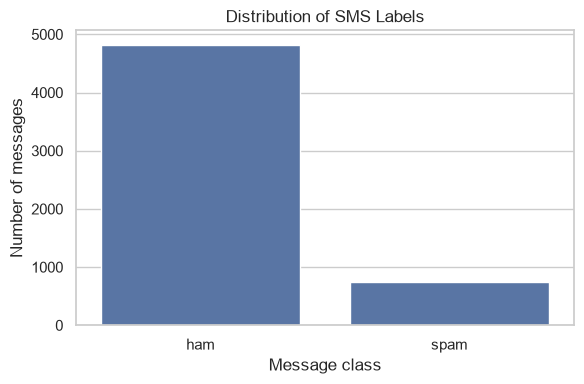

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("Distribution of SMS Labels")
plt.xlabel("Message class")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

The dataset is typically imbalanced, with legitimate messages outnumbering spam messages. For this reason, accuracy should be interpreted alongside precision, recall, and F1-score.

## 5. Prepare the Data

Remove rows with missing values, remove exact duplicate rows, normalize labels, and create a stratified train/test split. The test set is kept separate so it can provide an estimate of performance on unseen messages.

In [6]:
df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[(df["message"] != "") & (df["label"].isin(["ham", "spam"]))]
df = df.drop_duplicates().reset_index(drop=True)

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training messages: {len(X_train):,}")
print(f"Testing messages:  {len(X_test):,}")
print("\nTraining label proportions:")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

Training messages: 4,126
Testing messages:  1,032

Training label proportions:


,percentage
label,
ham,87.54
spam,12.46


## 6. Build Classification Pipelines

TF-IDF represents each message using weighted word features. Keeping vectorization inside a scikit-learn pipeline ensures that the vectorizer is fitted only on the training data and applies the same transformation at inference time.

We will compare:
- **Multinomial Naive Bayes** — a fast, commonly used baseline for text classification.
- **Logistic Regression** — a linear classifier that estimates class probabilities.
- **Linear Support Vector Classifier** — a linear-margin classifier that often performs well on sparse text features.


In [7]:
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2)),
        ("classifier", MultinomialNB()),
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("classifier", LinearSVC(random_state=RANDOM_STATE)),
    ]),
}

print(f"Prepared {len(models)} classification pipelines.")

Prepared 3 classification pipelines.


## 7. Train and Evaluate the Models

The models are trained on the training split and evaluated on the same held-out test split. Spam is treated as the positive class when calculating precision, recall, and F1-score.

In [8]:
results = []
trained_models = {}
predictions = {}

for model_name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": precision_score(y_test, y_pred, pos_label="spam", zero_division=0),
        "Spam Recall": recall_score(y_test, y_pred, pos_label="spam", zero_division=0),
        "Spam F1-score": f1_score(y_test, y_pred, pos_label="spam", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("Spam F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Spam Precision": "{:.4f}",
    "Spam Recall": "{:.4f}",
    "Spam F1-score": "{:.4f}",
}))

,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score
0,Linear SVM,0.9806,0.9655,0.8750,0.9180
1,Multinomial Naive Bayes,0.9690,1.0000,0.7500,0.8571
2,Logistic Regression,0.9603,0.9780,0.6953,0.8128


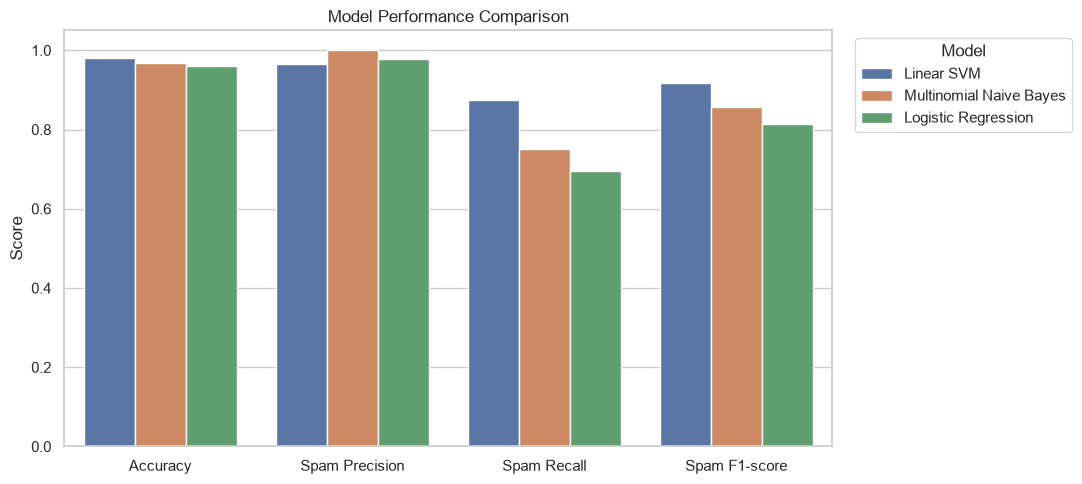

In [9]:
metrics_to_plot = ["Accuracy", "Spam Precision", "Spam Recall", "Spam F1-score"]
plot_df = results_df.melt(id_vars="Model", value_vars=metrics_to_plot,
                          var_name="Metric", value_name="Score")

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Inspect the Best Model

The best model is selected by test-set spam F1-score. F1-score balances precision and recall, which is useful when both missed spam and incorrectly flagged legitimate messages matter. The test set is used here for a straightforward comparison; in a larger project, model selection should be done using cross-validation on the training data, followed by a final evaluation on an untouched test set.

In [10]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print(f"Selected model: {best_model_name}")
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions, labels=["ham", "spam"],
    zero_division=0, digits=4
))

Selected model: Linear SVM

Classification report:
              precision    recall  f1-score   support

         ham     0.9825    0.9956    0.9890       904
        spam     0.9655    0.8750    0.9180       128

    accuracy                         0.9806      1032
   macro avg     0.9740    0.9353    0.9535      1032
weighted avg     0.9804    0.9806    0.9802      1032



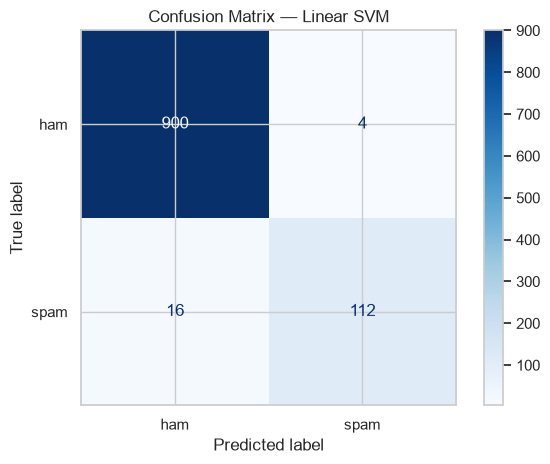

Rows = actual class; columns = predicted class.
Correctly classified ham:          900
Ham incorrectly flagged as spam:   4
Spam missed as ham:                16
Correctly classified spam:         112


In [11]:
cm = confusion_matrix(y_test, best_predictions, labels=["ham", "spam"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["ham", "spam"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print("Rows = actual class; columns = predicted class.")
print(f"Correctly classified ham:          {cm[0, 0]}")
print(f"Ham incorrectly flagged as spam:   {cm[0, 1]}")
print(f"Spam missed as ham:                {cm[1, 0]}")
print(f"Correctly classified spam:         {cm[1, 1]}")

## 9. Classify New Messages

Use the selected pipeline to classify messages not present in the dataset. The pipeline automatically applies the same TF-IDF transformation used during training.

In [12]:
sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward.",
    "Hi, are we still meeting for lunch tomorrow?",
    "URGENT! Your account has been selected for a cash reward. Reply now.",
]

sample_predictions = best_model.predict(sample_messages)
sample_output = pd.DataFrame({
    "message": sample_messages,
    "predicted_label": sample_predictions,
    "prediction": ["Spam" if label == "spam" else "Legitimate (ham)" for label in sample_predictions],
})
display(sample_output)

,message,predicted_label,prediction
0,Congratulations! You have won a free prize. Call now to claim your reward.,spam,Spam
1,"Hi, are we still meeting for lunch tomorrow?",ham,Legitimate (ham)
2,URGENT! Your account has been selected for a cash reward. Reply now.,spam,Spam


In [13]:
def classify_message(message: str) -> str:
    # Classify a single SMS message as spam or ham.
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please provide a non-empty text message.")

    predicted_label = best_model.predict([message])[0]
    return "Spam" if predicted_label == "spam" else "Legitimate (ham)"


# Edit this example to test your own message.
message_to_check = "Your package is ready for collection. Thank you."
print(classify_message(message_to_check))

Legitimate (ham)


## 10. Save the Trained Pipeline

Save the selected pipeline so the trained model and its TF-IDF vectorizer can be reused together. The output file is created in the notebook's current working directory.

In [14]:
MODEL_PATH = Path("sms_spam_detection_pipeline.joblib")
dump(best_model, MODEL_PATH)

print(f"Saved model pipeline to: {MODEL_PATH.resolve()}")

Saved model pipeline to: C:\Users\user\OIBSIP\OIBSIP\DataScience-Task4-EmailSpamDetection\sms_spam_detection_pipeline.joblib


## 11. Conclusions and Further Improvements

This project demonstrates an end-to-end text-classification workflow, from loading labelled messages to evaluating and saving a reusable model.

When reviewing the results, consider:
- **Spam recall:** How many actual spam messages were detected?
- **Spam precision:** How often was a message predicted as spam actually spam?
- **False positives:** Legitimate messages incorrectly flagged as spam can be particularly disruptive.
- **Generalization:** This dataset may not represent current messaging patterns, languages, or newer scam techniques.

Possible next steps include cross-validation, hyperparameter tuning, testing on a more recent dataset, examining false positives and false negatives, and deploying the saved pipeline in an application.

## Dataset and Method Notes

The notebook uses a public message spam dataset mirror and standard scikit-learn text-classification methods. Reported metrics are specific to the split and random seed used in this notebook. They should not be interpreted as a guarantee of performance on real-world messages.